# ЛР2. Техники валидации: линейная регрессия
Прогнозируем **Price ($)** по характеристикам смартфонов из `dataset.csv`.
Сравниваем семь вариантов кросс-валидации по RMSE, MAE и R². RMSE и MAE измеряются в долларах; меньше — лучше, для R² больше — лучше.
Временной метки нет, поэтому TimeSeriesSplit здесь не имеет содержательного обоснования.

In [8]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold,
                                     ShuffleSplit, GroupKFold, GroupShuffleSplit,
                                     LeaveOneGroupOut)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
NFOLDS = 5
plt.style.use('bmh')

## Данные и признаки
Приводим названия столбцов и единицы измерения к единому виду. Из описания камеры выделяем разрешение основной камеры и число камер. Название модели исключаем как идентификатор, бренд кодируем категориально.
Точные дубликаты удаляем до разбиения, чтобы одна и та же запись не попала одновременно в обучение и валидацию. Это не гарантирует независимость разных конфигураций одной модели телефона.

In [9]:
data = pd.read_csv('dataset.csv', encoding='utf-8-sig')
data.columns = data.columns.str.strip()
original_count = len(data)
data = data.drop_duplicates().reset_index(drop=True)

def first_number(value):
    match = re.search(r'\d+(?:\.\d+)?', str(value))
    return float(match.group()) if match else np.nan

for column in ['Storage', 'RAM', 'Screen Size (inches)',
               'Battery Capacity (mAh)', 'Price ($)']:
    data[column] = data[column].map(first_number)
data['Main camera (MP)'] = data['Camera (MP)'].map(first_number)
data['Camera count'] = data['Camera (MP)'].map(
    lambda value: len(re.findall(r'\d+(?:\.\d+)?', str(value))) or np.nan)
data['Brand'] = data['Brand'].astype('string').str.strip().fillna('Unknown').astype(str)
data = data.dropna(subset=['Price ($)']).reset_index(drop=True)
print(f'Исходных строк: {original_count}; после очистки: {len(data)}')
display(data.head())
display(data.describe(include='all'))

Исходных строк: 407; после очистки: 381


,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($),Main camera (MP),Camera count
0,Apple,iPhone 13 Pro,128.0,6.0,6.10,12 + 12 + 12,3095.0,999.0,12.0,3
1,Samsung,Galaxy S21 Ultra,256.0,12.0,6.80,108 + 10 + 10 + 12,5000.0,1199.0,108.0,4
2,OnePlus,9 Pro,128.0,8.0,6.70,48 + 50 + 8 + 2,4500.0,899.0,48.0,4
3,Xiaomi,Redmi Note 10 Pro,128.0,6.0,6.67,64 + 8 + 5 + 2,5020.0,279.0,64.0,4
4,Google,Pixel 6,128.0,8.0,6.40,50 + 12.2,4614.0,799.0,50.0,2


,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($),Main camera (MP),Camera count
count,381,381,381.000000,381.000000,381.000000,381,381.000000,381.000000,381.000000,381.000000
unique,16,239,NaN,NaN,NaN,143,NaN,NaN,NaN,NaN
top,Samsung,C21Y,NaN,NaN,NaN,13MP + 2MP + 2MP,NaN,NaN,NaN,NaN
freq,73,5,NaN,NaN,NaN,28,NaN,NaN,NaN,NaN
mean,NaN,NaN,124.556430,5.879265,6.475932,NaN,4683.958005,402.010499,43.568504,3.144357
std,NaN,NaN,66.124485,2.466857,0.310012,NaN,792.927831,298.398444,24.730962,0.772999
min,NaN,NaN,32.000000,2.000000,4.500000,NaN,1821.000000,1.000000,8.000000,1.000000
25%,NaN,NaN,64.000000,4.000000,6.440000,NaN,4300.000000,199.000000,13.000000,3.000000
50%,NaN,NaN,128.000000,6.000000,6.500000,NaN,5000.000000,299.000000,48.000000,3.000000
75%,NaN,NaN,128.000000,8.000000,6.580000,NaN,5000.000000,469.000000,64.000000,4.000000


## Общая тестовая выборка и модель
Сначала откладываем 20% записей в общий test. Все варианты CV используют только остальные 80% и одинаковые признаки. Test не участвует в обучении, импутации или масштабировании.
В каждом фолде создаётся новая Pipeline: заполнение пропусков, масштабирование числовых признаков, OneHotEncoder бренда и **LinearRegression**. Неизвестные бренды допускаются кодировщиком.

In [10]:
numeric = ['Storage', 'RAM', 'Screen Size (inches)', 'Battery Capacity (mAh)',
           'Main camera (MP)', 'Camera count']
X = data[numeric + ['Brand']]
y = data['Price ($)']
train_ids, test_ids = train_test_split(np.arange(len(data)), test_size=0.2, random_state=SEED)
# Сортировка сохраняет порядок строк CSV для схем фолдов, но не означает порядок во времени.
train_ids, test_ids = np.sort(train_ids), np.sort(test_ids)
X_train, X_test = X.iloc[train_ids].reset_index(drop=True), X.iloc[test_ids].reset_index(drop=True)
y_train, y_test = y.iloc[train_ids].reset_index(drop=True), y.iloc[test_ids].reset_index(drop=True)
groups = X_train['Brand'].to_numpy()
preprocess = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), numeric),
    ('brand', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Brand'])
])
model = Pipeline([('preprocess', preprocess), ('regression', LinearRegression())])
print(f'Train: {len(X_train)}, test: {len(X_test)}, брендов в train: {len(set(groups))}')

Train: 304, test: 77, брендов в train: 16


## Варианты валидации
1. KFold без перемешивания — последовательные блоки исходных строк.
2. KFold с перемешиванием — каждый объект ровно один раз в validation.
3. RepeatedKFold — пять фолдов, три повторения с разными разбиениями.
4. ShuffleSplit — пять случайных разбиений 80/20; validation может пересекаться между итерациями.
5. GroupKFold по бренду — бренды train и validation не пересекаются.
6. GroupShuffleSplit по бренду — случайные 20% **брендов**, а не строк, для validation.
7. LeaveOneGroupOut — на каждой итерации один бренд целиком исключается из обучения.

Групповые методы проверяют перенос на неизвестные бренды, поэтому решают более сложную задачу, чем случайные разбиения. Общий случайный test отражает прогноз для смеси брендов и не является отдельным тестом на неизвестный бренд.

In [11]:
methods = {
    'KFold без перемешивания': KFold(n_splits=NFOLDS),
    'KFold с перемешиванием': KFold(n_splits=NFOLDS, shuffle=True, random_state=SEED),
    'RepeatedKFold (5 × 3)': RepeatedKFold(n_splits=NFOLDS, n_repeats=3, random_state=SEED),
    'ShuffleSplit': ShuffleSplit(n_splits=NFOLDS, test_size=0.2, random_state=SEED),
    'GroupKFold (бренд)': GroupKFold(n_splits=NFOLDS),
    'GroupShuffleSplit (бренд)': GroupShuffleSplit(n_splits=NFOLDS, test_size=0.2, random_state=SEED),
    'LeaveOneGroupOut (бренд)': LeaveOneGroupOut(),
}
group_methods = {'GroupKFold (бренд)', 'GroupShuffleSplit (бренд)', 'LeaveOneGroupOut (бренд)'}

def evaluate(name, splitter):
    splits = list(splitter.split(X_train, y_train, groups=groups) if name in group_methods
                  else splitter.split(X_train, y_train))
    rows = []
    for fold, (train_idx, valid_idx) in enumerate(splits, start=1):
        assert len(np.intersect1d(train_idx, valid_idx)) == 0
        if name in group_methods:
            assert set(groups[train_idx]).isdisjoint(groups[valid_idx])
        fitted = clone(model).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        prediction = fitted.predict(X_train.iloc[valid_idx])
        rows.append({'Метод': name, 'Фолд': fold, 'Train': len(train_idx),
                     'Validation': len(valid_idx),
                     'RMSE': np.sqrt(mean_squared_error(y_train.iloc[valid_idx], prediction)),
                     'MAE': mean_absolute_error(y_train.iloc[valid_idx], prediction),
                     'R²': r2_score(y_train.iloc[valid_idx], prediction) if len(valid_idx) > 1 else np.nan})
    return splits, rows

splits_by_method, records = {}, []
for name, splitter in methods.items():
    splits_by_method[name], rows = evaluate(name, splitter)
    records.extend(rows)
fold_metrics = pd.DataFrame(records)
summary = fold_metrics.groupby('Метод', sort=False).agg(
    Folds=('Фолд', 'count'), RMSE_mean=('RMSE', 'mean'), RMSE_std=('RMSE', 'std'),
    MAE_mean=('MAE', 'mean'), R2_mean=('R²', 'mean'),
    Train_mean=('Train', 'mean'), Validation_mean=('Validation', 'mean'))
display(summary.round(3))
print('Std — выборочное стандартное отклонение между фолдами, не доверительный интервал.')
print('R² для фолда с одним объектом не определён и исключается из среднего.')

,Folds,RMSE_mean,RMSE_std,MAE_mean,R2_mean,Train_mean,Validation_mean
Метод,,,,,,,
KFold без перемешивания,5,162.017,76.801,106.354,0.523,243.2,60.8
KFold с перемешиванием,5,158.888,18.648,98.784,0.675,243.2,60.8
RepeatedKFold (5 × 3),15,156.873,26.109,98.541,0.697,243.2,60.8
ShuffleSplit,5,158.814,27.018,101.080,0.711,243.0,61.0
GroupKFold (бренд),5,226.372,35.131,182.775,0.324,243.2,60.8
GroupShuffleSplit (бренд),5,285.838,74.968,240.738,-0.161,244.0,60.0
LeaveOneGroupOut (бренд),16,266.844,144.416,240.682,-2.545,285.0,19.0


Std — выборочное стандартное отклонение между фолдами, не доверительный интервал.
R² для фолда с одним объектом не определён и исключается из среднего.


## Распределение сэмплов по фолдам
Каждая колонка слева — один объект обучающей части в порядке исходного CSV; каждая строка — фолд. Синий — train, оранжевый — validation, серый — не используется. Справа показаны размеры частей. Финальный test отложен заранее и в схемы CV не входит.

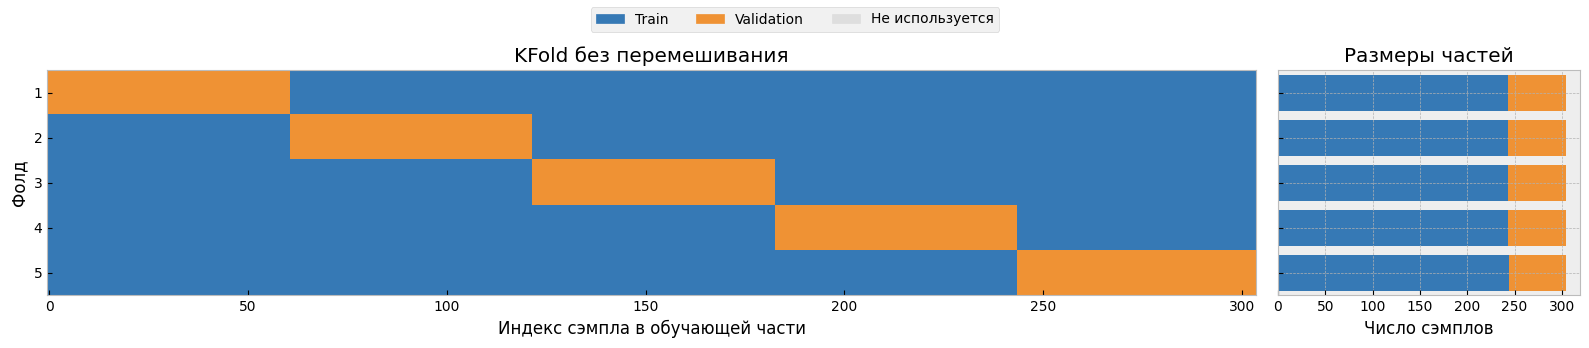

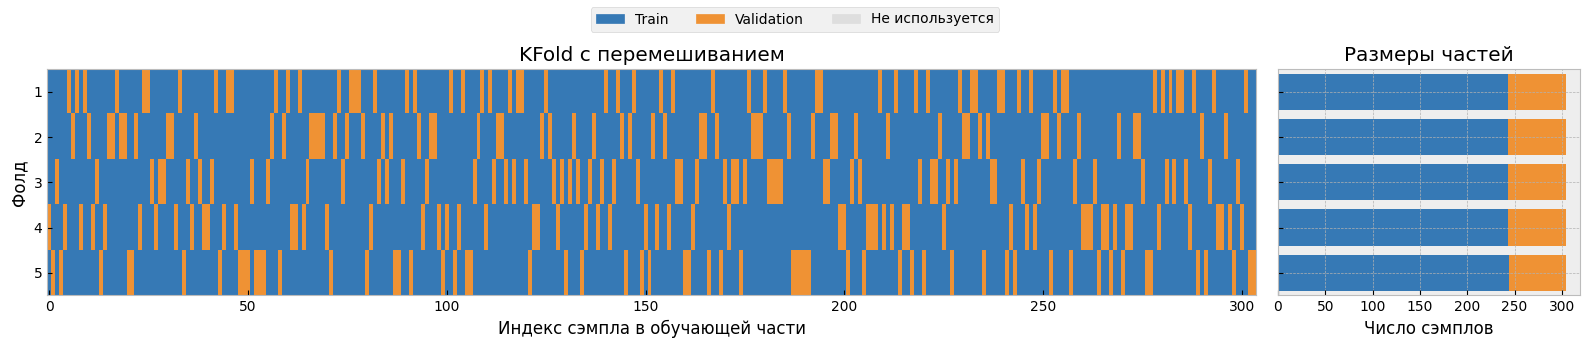

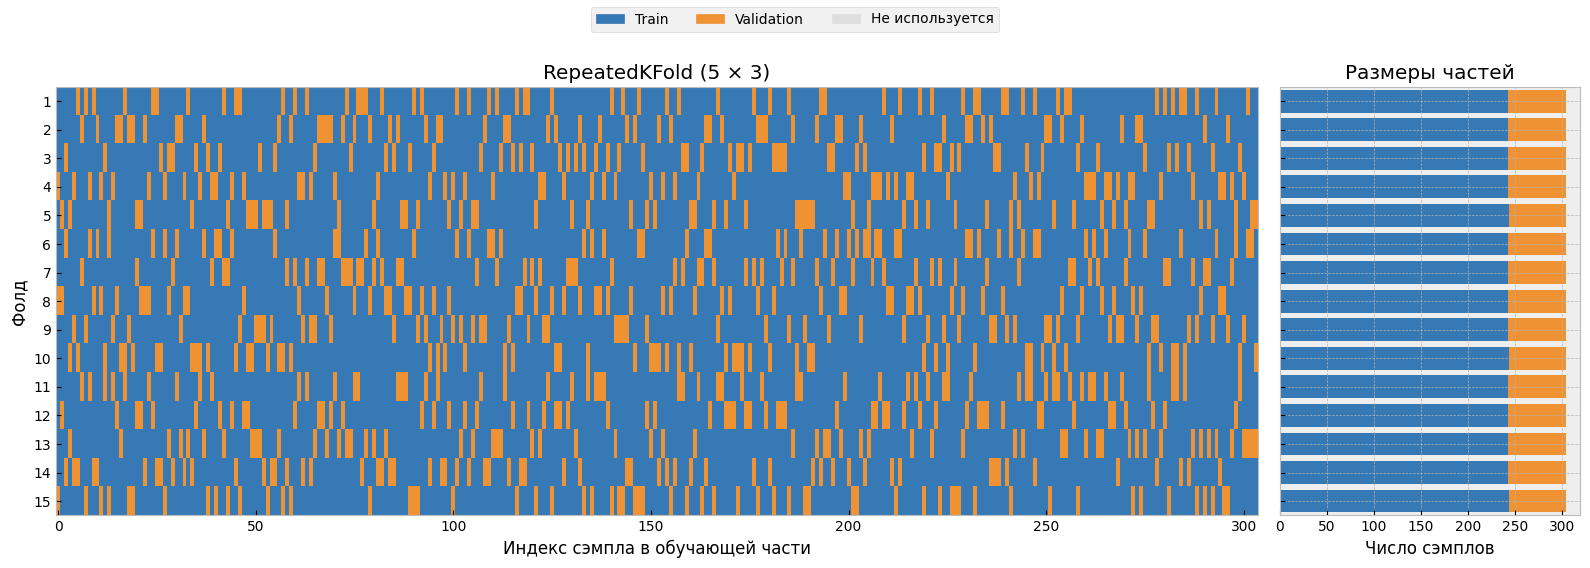

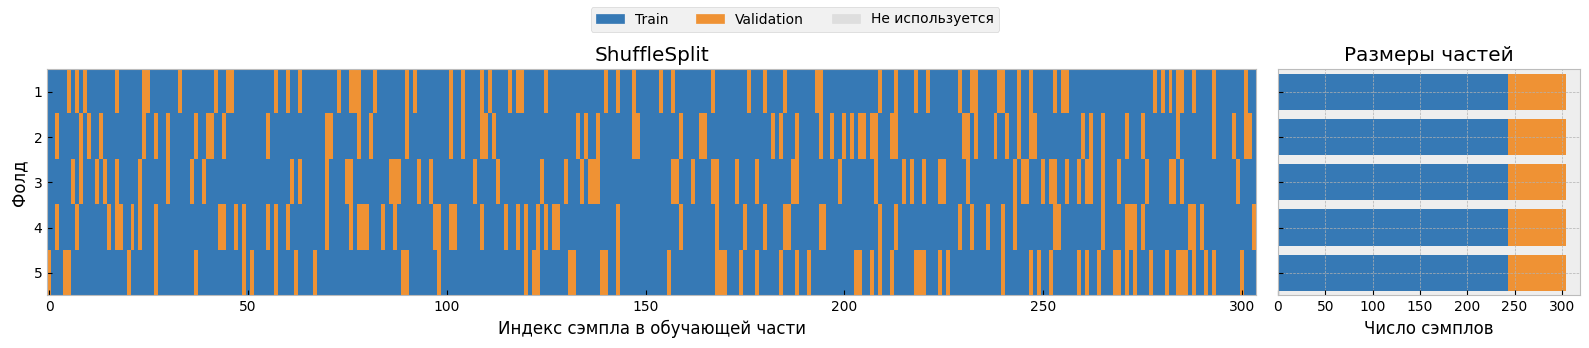

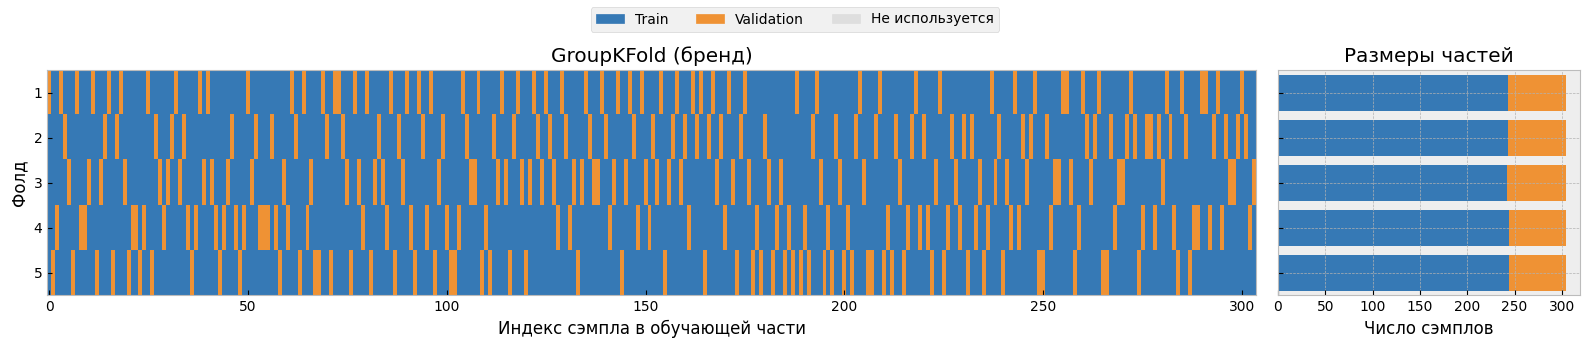

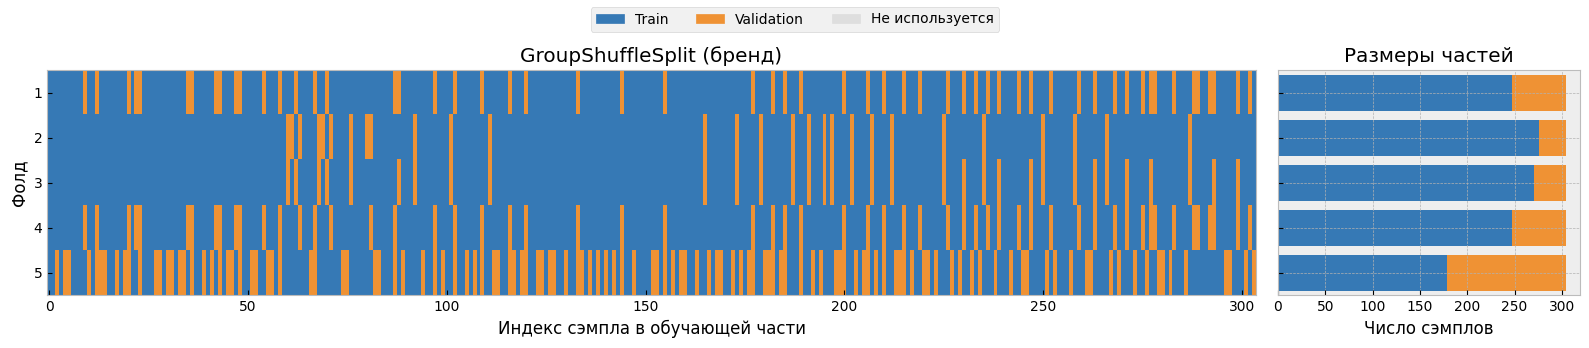

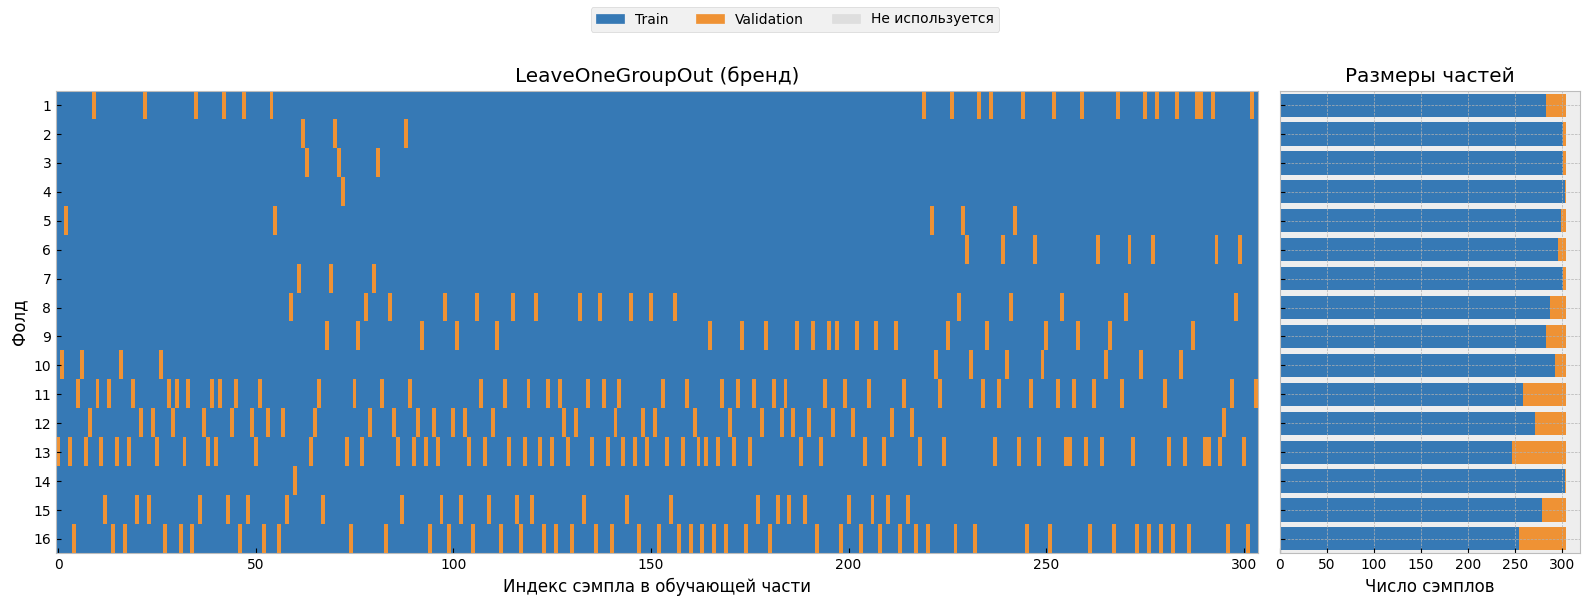

In [12]:
def plot_cv(name, splits):
    membership = np.zeros((len(splits), len(X_train)), dtype=int)
    for row, (train_idx, valid_idx) in enumerate(splits):
        membership[row, train_idx] = 1
        membership[row, valid_idx] = 2
    fig, axes = plt.subplots(1, 2, figsize=(16, max(3.5, len(splits) * 0.38)),
                             gridspec_kw={'width_ratios': [4, 1]}, sharey=True)
    axes[0].imshow(membership, aspect='auto', interpolation='nearest',
                   cmap=ListedColormap(['#dedede', '#3679b5', '#ef9234']), vmin=0, vmax=2)
    axes[0].set(xlabel='Индекс сэмпла в обучающей части', ylabel='Фолд', title=name)
    axes[0].set_yticks(np.arange(len(splits)), np.arange(1, len(splits) + 1))
    axes[0].grid(False)
    rows = np.arange(len(splits))
    axes[1].barh(rows, [len(t) for t, v in splits], color='#3679b5', label='Train')
    axes[1].barh(rows, [len(v) for t, v in splits],
                 left=[len(t) for t, v in splits], color='#ef9234', label='Validation')
    axes[1].set(xlabel='Число сэмплов', title='Размеры частей')
    fig.legend(handles=[Patch(color='#3679b5', label='Train'),
                        Patch(color='#ef9234', label='Validation'),
                        Patch(color='#dedede', label='Не используется')],
               loc='upper center', ncol=3)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

for name, splits in splits_by_method.items():
    plot_cv(name, splits)

## Сравнение результатов и финальная проверка
Средние метрики вычисляются с одинаковым весом фолдов; при разных размерах групп это не равно ошибке по всем объектам. Фолды и повторы зависимы, поэтому разброс не интерпретируется как статистическая значимость различий.
После CV обучаем одну фиксированную линейную регрессию на всей обучающей части и один раз оцениваем на общем test. Модель и признаки во всех экспериментах одинаковы, поэтому общий test результат один, а не отдельный для каждого способа разбиения.

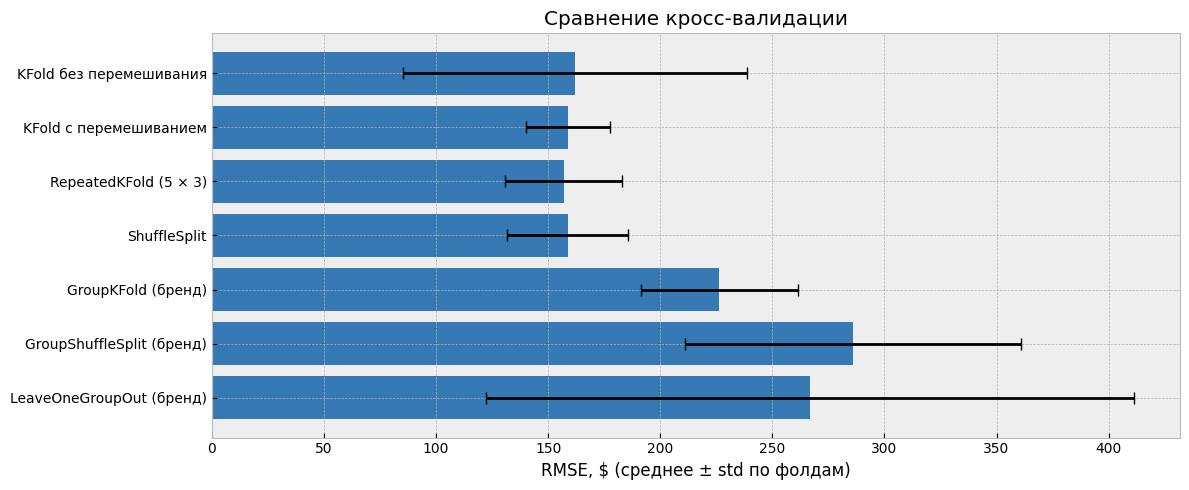

RMSE    118.945
MAE      86.796
R²        0.844
Name: Общий test, dtype: float64

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
positions = np.arange(len(summary))
ax.barh(positions, summary['RMSE_mean'], xerr=summary['RMSE_std'], capsize=4, color='#3679b5')
ax.set_yticks(positions, summary.index)
ax.invert_yaxis()
ax.set(xlabel='RMSE, $ (среднее ± std по фолдам)', title='Сравнение кросс-валидации')
fig.tight_layout()
plt.show()

final_model = clone(model).fit(X_train, y_train)
test_prediction = final_model.predict(X_test)
test_metrics = pd.Series({'RMSE': np.sqrt(mean_squared_error(y_test, test_prediction)),
                          'MAE': mean_absolute_error(y_test, test_prediction),
                          'R²': r2_score(y_test, test_prediction)}, name='Общий test')
display(test_metrics.round(3))
assert len(summary) >= 5
assert all(np.isfinite(fold_metrics['RMSE']))

In [14]:
best = summary['RMSE_mean'].idxmin()
worst = summary['RMSE_mean'].idxmax()
print(f'Минимальный средний CV RMSE: {best} — {summary.loc[best, "RMSE_mean"]:.2f}$.')
print(f'Максимальный средний CV RMSE: {worst} — {summary.loc[worst, "RMSE_mean"]:.2f}$.')
print(f'RMSE на общем test: {test_metrics["RMSE"]:.2f}$.')

Минимальный средний CV RMSE: RepeatedKFold (5 × 3) — 156.87$.
Максимальный средний CV RMSE: GroupShuffleSplit (бренд) — 285.84$.
RMSE на общем test: 118.95$.


Для прогноза телефонов известных брендов подходит KFold с перемешиванием; RepeatedKFold позволяет оценить чувствительность к разбиению. Для новых брендов нужны групповые методы. Минимальная ошибка сама по себе не делает способ валидации лучшим: он должен соответствовать применению модели.

## Вывод по полученным результатам
Для случайных разбиений средний RMSE близок: **156,87–158,89 $** у RepeatedKFold, ShuffleSplit и KFold с перемешиванием. RepeatedKFold даёт минимальное среднее, но разница невелика относительно разброса по фолдам и не доказывает превосходство метода.

Без перемешивания RMSE равен **162,02$**, а стандартное отклонение — **76,80$**, против **18,65$** у KFold с перемешиванием. Результат сильнее зависит от последовательных блоков строк CSV.

При исключении брендов ошибки выше: GroupKFold — **226,37$**, GroupShuffleSplit — **285,84$**, LeaveOneGroupOut — **266,84$**. Это указывает на более слабый перенос линейной модели на неизвестные бренды. Средний R² у последних двух методов отрицателен; для LeaveOneGroupOut оценка также чувствительна к малым группам и узкому диапазону цен внутри бренда.

На общем отложенном test RMSE составляет **118,95$**. Это оценка одного случайного разбиения, поэтому её отличие от среднего CV не означает улучшение модели. Для задачи с известными брендами используем KFold с перемешиванием или RepeatedKFold; если ожидаются новые бренды, ориентируемся на групповые разбиения.
